# Tufa Labs ARC3 submission

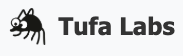

This notebook executes the ARC-AGI-3 solver written by the Tufa Labs team; in alphabetical order: Harold Bessis, Jeroen Cottaar, Isaiah Pressman, Andries Smit, Michal Tesnar, and Stefano Viel.

You will only find infrastructure and diagnostics in this notebook; the actual solver code is in an attached dataset. See our writeup on the competition forum to learn more about that the solver actually does.

It installs the ARC runtime from the competition wheelhouse, makes the bundled source
snapshot importable, runs any solver setup commands, loads the pickled benchmark, plays the
competition games, and writes results to `/kaggle/working`. Diagnostics are minimised during
a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`) and kept full otherwise.

## 1. Environment and submission mode

Detect whether this is a real competition rerun (which minimises diagnostics), set the
framework's environment flags, and put the CUDA libraries on the linker path.

In [1]:
import json
import os
import pickle
import subprocess
import sys
import sysconfig
import time
from datetime import datetime, timedelta
from pathlib import Path
from urllib.request import urlopen

# True only inside a real competition rerun; switches diagnostics + soft deadline.
TRUE_SUBMISSION = os.environ.get("KAGGLE_IS_COMPETITION_RERUN", "").strip().lower() in {"1", "true"}
NOTEBOOK_START_EPOCH = time.time()

# Non-interactive matplotlib backend: diagnostics render plots with no display attached.
os.environ["MPLBACKEND"] = "Agg"
# Marks the run as a (real or emulated) submission so the framework + solver can adjust.
os.environ["TAAF_RUN_AS_SUBMISSION"] = "1" if TRUE_SUBMISSION else "0"
# In submission, disable the periodic JSON/HTML diagnostics writes and per-frame logging.
os.environ["TAAF_MINIMAL_DIAGNOSTICS"] = "1" if TRUE_SUBMISSION else "0"
# Pin arc_agi's cached level_reset_only before its client is built (RESET keeps the level).
os.environ["ONLY_RESET_LEVELS"] = "true"

# Prepend the CUDA toolkit to the linker path (it is off it on Kaggle GPU images) so the
# solver's GPU libraries (e.g. vllm / torch) can link against libcuda.
cuda_library_path = "/usr/local/nvidia/lib64"
os.environ["LIBRARY_PATH"] = os.pathsep.join(
    entry for entry in [cuda_library_path, *os.environ.get("LIBRARY_PATH", "").split(os.pathsep)] if entry
)

# Everything the run produces is written here.
WORKING_DIR = Path("/kaggle/working")
WORKING_DIR.mkdir(parents=True, exist_ok=True)
print(f"taaf.kaggle: TRUE_SUBMISSION={TRUE_SUBMISSION}")

taaf.kaggle: TRUE_SUBMISSION=False


## 2. Install the ARC runtime

Install `arc-agi` from the offline competition wheelhouse (the Kaggle submission environment
has no internet).

In [2]:
# Install the ARC runtime from the bundled competition wheels.
# Quiet: stdout is discarded; stderr (and a non-zero exit) still surface real failures.
subprocess.check_call(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "--quiet",
        "--no-index",
        "--no-warn-conflicts",
        "--disable-pip-version-check",
        "--find-links",
        "/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels",
        "arc-agi",
    ],
    stdout=subprocess.DEVNULL,
)

0

## 3. Locate the source bundle

Find the uploaded TAAF source dataset by its marker file, and record where Kaggle mounted
every attached input so setup commands and the solver can find them.

In [3]:
# Kaggle inputs attached to this notebook, plus bookkeeping paths used below.
DATASET_SOURCES = ["stephenkaskin/taaf-kaggle-source-duck-virelai-r0", "driessmit1/arc3-vllm-h100-wheelhouse-v3", "driessmit1/vrfai-qwen3-6-27b-fp8-hf-snapshot"]
KERNEL_SOURCES = []
DATASET_BUNDLE_MARKER = "taaf-kaggle-bundle.json"
SETUP_ENV_PATH = WORKING_DIR / "taaf_setup_env.json"


# Locate the source dataset by its marker file rather than a fixed mount path.
def _find_bundle_dir() -> Path:
    for marker in Path("/kaggle/input").rglob(DATASET_BUNDLE_MARKER):
        return marker.parent
    raise RuntimeError("TAAF source bundle not found under /kaggle/input.")


# Kaggle mounts a dataset at /kaggle/input/<slug> or /kaggle/input/datasets/<owner>/<slug>
# (depending on owner / slug collisions), so probe both and use whichever exists. Utility
# scripts mount under /kaggle/usr/lib/notebooks/<owner>/<slug>.
def _dataset_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/input") / slug, Path("/kaggle/input/datasets") / owner / slug]


def _kernel_mount_candidates(ref: str) -> list[Path]:
    owner, slug = ref.split("/", 1)
    return [Path("/kaggle/usr/lib/notebooks") / owner / slug]


def _first_existing(candidates: list[Path]) -> Path | None:
    return next((c for c in candidates if c.exists()), None)


BUNDLE_DIR = _find_bundle_dir()
print(f"taaf.kaggle: source bundle = {BUNDLE_DIR}")

# Map each attached input to where Kaggle actually mounted it (the source bundle is index 0).
kaggle_input_paths: dict[str, str] = {}
for i, ref in enumerate(DATASET_SOURCES):
    candidates = _dataset_mount_candidates(ref)
    resolved = BUNDLE_DIR if i == 0 else _first_existing(candidates)
    kaggle_input_paths[ref] = str(resolved or candidates[0])
for ref in KERNEL_SOURCES:
    candidates = _kernel_mount_candidates(ref)
    kaggle_input_paths[ref] = str(_first_existing(candidates) or candidates[0])

# Published to setup commands and the solver via the environment:
setup_env = {
    # JSON {ref: mount_path} so they can locate every attached dataset / utility script.
    "TAAF_KAGGLE_INPUT_PATHS": json.dumps(kaggle_input_paths, sort_keys=True),
    # The attached dataset refs in order (index 0 is this source bundle).
    "TAAF_KAGGLE_DATASET_SOURCES": json.dumps(DATASET_SOURCES),
    # The attached utility-script / kernel refs.
    "TAAF_KAGGLE_KERNEL_SOURCES": json.dumps(KERNEL_SOURCES),
}
os.environ.update(setup_env)
SETUP_ENV_PATH.write_text(json.dumps(setup_env, indent=2, sort_keys=True) + "\n")
print(f"taaf.kaggle: input paths = {setup_env['TAAF_KAGGLE_INPUT_PATHS']}")

taaf.kaggle: source bundle = /kaggle/input/datasets/stephenkaskin/taaf-kaggle-source-duck-virelai-r0
taaf.kaggle: input paths = {"driessmit1/arc3-vllm-h100-wheelhouse-v3": "/kaggle/input/datasets/driessmit1/arc3-vllm-h100-wheelhouse-v3", "driessmit1/vrfai-qwen3-6-27b-fp8-hf-snapshot": "/kaggle/input/datasets/driessmit1/vrfai-qwen3-6-27b-fp8-hf-snapshot", "stephenkaskin/taaf-kaggle-source-duck-virelai-r0": "/kaggle/input/datasets/stephenkaskin/taaf-kaggle-source-duck-virelai-r0"}


## 4. Import the bundled source and run solver setup

Put the snapshotted repositories on the path (this process and any child processes), then run
the solver's setup commands — installing wheels, fetching model weights, and so on.

In [4]:
# Each bundled repo exposes its importable tree at <repo>/src or <repo>.
def _source_path_entries(bundle_dir: Path) -> list:
    entries = []
    for repo in sorted((bundle_dir / "src").iterdir(), reverse=True):
        for candidate in (repo / "src", repo):
            if candidate.is_dir():
                entries.append(candidate)
    return entries


# Environment handed to each setup command (paths + any keys it has persisted).
def _command_env() -> dict:
    env = os.environ.copy()
    # "$PYTHON" in a command resolves to this notebook's interpreter.
    env["PYTHON"] = sys.executable
    # Absolute path to the mounted source bundle.
    env["TAAF_KAGGLE_BUNDLE_DIR"] = str(BUNDLE_DIR)
    # The writable /kaggle/working directory.
    env["TAAF_KAGGLE_WORKING_DIR"] = str(WORKING_DIR)
    # A command writes a JSON object here to persist env keys to later commands + the run.
    env["TAAF_KAGGLE_SETUP_ENV"] = str(SETUP_ENV_PATH)
    env.update({str(k): str(v) for k, v in json.loads(SETUP_ENV_PATH.read_text()).items()})
    return env


# Make the bundled repos importable here (sys.path) and in child processes (.pth).
source_entries = _source_path_entries(BUNDLE_DIR)
for entry in source_entries:
    sys.path.insert(0, str(entry))
pth_path = Path(sysconfig.get_paths()["purelib"]) / "taaf_kaggle_sources.pth"
pth_path.write_text("".join(f"{entry}\n" for entry in source_entries))
print(f"taaf.kaggle: wrote {pth_path} ({len(source_entries)} source roots)")

# Solver setup commands (wheels, vLLM server startup, ...) run before the benchmark loads.
env = _command_env()
for command in json.loads((BUNDLE_DIR / "setup_commands.json").read_text()):
    print(f"taaf.kaggle: setup command: {command}", flush=True)
    subprocess.run(command, shell=True, check=True, cwd=WORKING_DIR, env=env)
    # Re-read in case the command persisted new env keys.
    env = _command_env()
    os.environ.update(env)

# Honour any PYTHONPATH a setup command exported.
for entry in reversed([e for e in os.environ.get("PYTHONPATH", "").split(os.pathsep) if e]):
    if entry not in sys.path:
        sys.path.insert(0, entry)

taaf.kaggle: wrote /usr/local/lib/python3.12/dist-packages/taaf_kaggle_sources.pth (3 source roots)
taaf.kaggle: setup command: "$PYTHON" - <<'PYSETUP'
import json
import os
import shutil
import subprocess
import sys
import time
import urllib.request
from pathlib import Path

WHEELHOUSE_OWNER = 'driessmit1'
WHEELHOUSE_SLUG = 'arc3-vllm-h100-wheelhouse-v3'
MODEL_OWNER = 'driessmit1'
MODEL_SLUG = 'vrfai-qwen3-6-27b-fp8-hf-snapshot'
SERVED_MODEL_NAME = 'vrfai/Qwen3.6-27B-FP8'
VLLM_HOST = '127.0.0.1'
VLLM_PORT = 1234
VLLM_BASE_URL = f'http://{VLLM_HOST}:{VLLM_PORT}/v1'
VLLM_MAX_MODEL_LEN = 65536
ANALYZER_CONTEXT_WINDOW = 32768
VLLM_TENSOR_PARALLEL_SIZE = 1
WORKING_DIR = Path(os.environ['TAAF_KAGGLE_WORKING_DIR'])
SITE_PACKAGES = WORKING_DIR / 'vllm-site-packages'
VLLM_SERVER_LOG = WORKING_DIR / 'vllm-openai-server.log'
VLLM_SERVER_PID = WORKING_DIR / 'vllm-openai-server.pid'
INSTALL_STAMP = SITE_PACKAGES / f'.{WHEELHOUSE_SLUG}'
STAMP_TEXT = 'vllm==0.19.0 torch==2.10.0 flashinfer==0.6.6\n'


## 5. Load the benchmark

Unpickle the deployment target and the benchmark, stamping the real submission state onto the
target and pointing the benchmark's outputs at the Kaggle working directory.

In [5]:
# Restore the deployment target and record the real submission state on it.
with open(BUNDLE_DIR / "deploy_target.pkl", "rb") as file:
    target = pickle.load(file)
target.actual_run_as_submission = TRUE_SUBMISSION
target.is_competition_rerun = TRUE_SUBMISSION

# Restore the benchmark and point its outputs at the Kaggle working dir.
with open(BUNDLE_DIR / "benchmark_initial.pkl", "rb") as file:
    bm = pickle.load(file)
bm.job_dir = WORKING_DIR

## 6. Customization hook

Optional: tweak `bm`, `bm.games`, or `bm.solver` here before the run starts — the safe place
for one-off experiments once the deployed bundle has loaded.

In [6]:
# Make one-off changes to `bm`, `bm.games`, or `bm.solver` here before the run starts.
# Example:
# bm.label = f"{bm.label}-debug"

## 7. Run the benchmark

In a real competition rerun (`KAGGLE_IS_COMPETITION_RERUN`), wait for the Kaggle gateway and
play the **live competition Arcade**. Otherwise — an interactive "Save & Run" — play the
competition's **bundled environment files offline**, with no gateway required, so the notebook
runs end-to-end without a submission. Teardown commands run afterward even if the run raises.

In [7]:
# Build the live competition game list from the gateway's available environments.
def _competition_games():
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=os.environ["ARC_BASE_URL"],
        environments_dir="",
    )
    arcade = arc_agi.Arcade(
        operation_mode=arc_agi.OperationMode.COMPETITION,
        arc_base_url=spec.arc_base_url,
        environments_dir="",
    )
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError("Competition Arcade exposed zero environments.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# Build the offline game list from the competition's bundled environment files.
def _offline_games(env_dir: str):
    import arc_agi

    import taaf.game_api

    spec = taaf.game_api.ArcadeSpec(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    arcade = arc_agi.Arcade(operation_mode=arc_agi.OperationMode.OFFLINE, environments_dir=env_dir)
    game_ids = [env_info.game_id for env_info in arcade.available_environments]
    if not game_ids:
        raise RuntimeError(f"No offline environments found under {env_dir}.")
    return [taaf.game_api.GameAPI(env_name=game_id, arcade_spec=spec) for game_id in game_ids]


# The gateway can take a while to come up; poll until it answers.
def _wait_for_gateway(base_url: str, timeout_s: float = 600.0) -> None:
    deadline = time.monotonic() + timeout_s
    last_error = ""
    while time.monotonic() < deadline:
        try:
            with urlopen(f"{base_url}api/games", timeout=10) as response:
                if response.status < 500:
                    return
        except Exception as exc:
            last_error = repr(exc)
        time.sleep(5)
    raise RuntimeError(f"Kaggle gateway did not become ready: {last_error}")


# Print the run preamble and persist the launcher's git status for diagnostics.
print((BUNDLE_DIR / "preamble.txt").read_text())
(WORKING_DIR / "git_status.txt").write_text((BUNDLE_DIR / "git_status.txt").read_text())

# arc_agi reads RECORDINGS_DIR and ARC_API_KEY from env (ArcadeSpec carries neither); operation
# mode, environments dir, and base url are all passed explicitly via the spec, so no env is needed.
os.environ.setdefault("RECORDINGS_DIR", str(WORKING_DIR / "server_recording"))

if TRUE_SUBMISSION:
    # Real submission: play the live competition Arcade served by the Kaggle gateway.
    os.environ.setdefault("ARC_API_KEY", "test-key-123")
    os.environ.setdefault("ARC_BASE_URL", "http://gateway:8001/")
    # The gateway boots asynchronously; wait before swapping in its game list.
    _wait_for_gateway(os.environ["ARC_BASE_URL"])
    bm.games = _competition_games()
else:
    # Interactive run: play the bundled competition environments offline (no gateway).
    # The competition's environment files ship alongside the wheelhouse in the competition dataset.
    competition_env_files = str(Path("/kaggle/input/competitions/arc-prize-2026-arc-agi-3/arc_agi_3_wheels").parent / "environment_files")
    bm.games = _offline_games(competition_env_files)

bm.n_passes = 1
bm.game_weights = None

# Outside a real submission, stop ~10 min before the wall-clock budget for a graceful exit.
soft_end = None
if not TRUE_SUBMISSION:
    budget = float(getattr(target, "max_runtime_s", 0.0) or 0.0)
    if budget > 0:
        soft_end = datetime.fromtimestamp(NOTEBOOK_START_EPOCH) + timedelta(seconds=budget - min(600.0, budget / 2))

# Play the benchmark; teardown commands run even if the run raises.
try:
    await bm.run(soft_end_time=soft_end, runtime_environment=target, minimal_diagnostics=TRUE_SUBMISSION)
    if not TRUE_SUBMISSION:
        # An offline run isn't scored, but Kaggle still expects a submission.parquet output.
        import pandas as pd

        pd.DataFrame(
            [["1_0", "1", True, 1]],
            columns=["row_id", "game_id", "end_of_game", "score"],
        ).to_parquet(WORKING_DIR / "submission.parquet", index=False)
finally:
    for command in json.loads((BUNDLE_DIR / "teardown_commands.json").read_text()):
        print(f"taaf.kaggle: teardown command: {command}", flush=True)
        subprocess.run(command, shell=True, check=False, cwd=WORKING_DIR, env=_command_env())

benchmark.label : duck-virelai-r0-dryrun
benchmark.solver: HarnessSolver(label='duck-harness', runtime_environment=None, job_dir=None, soft_end_time=None, minimal_diagnostics=False, model='local', analyzer_timeout=900.0, max_actions_per_game=None, max_runtime_s_per_game=7920.0, concurrency=28, save_request_logs=False, start_local_server=False, local_server_config='', local_server_api_key_file='', local_server_repo_dir='/home/claude/duck-virelai/baseline/duck-harness/ARC3-Inference', local_server_port=None, local_server_tensor_parallel_size=None, local_server_count=1, cancel_drain_timeout_s=120.0)
benchmark.passes: 1
benchmark.games : 25
git status:
  ARC3-Inference                   7143ad5     DIRTY  main                      CORRECTIVE: complete the baseline freeze — first freeze sil…
  tufa-arc-agi-framework           7143ad5     DIRTY  main                      CORRECTIVE: complete the baseline freeze — first freeze sil…
benchmark: regenerated diagnostics in /kaggle/working in 2.45

analyzer request failed at action 35: HTTPConnectionPool(host='127.0.0.1', port=1234): Read timed out. (read timeout=900.0)


benchmark: regenerated diagnostics in /kaggle/working in 2.54s
benchmark: duck-virelai-r0-dryrun
solver:    duck-harness
games:     25
passes:    1
runs:      25 (won: 0)
started:   2026-08-23 18:23:56
ended:     in progress
mean score:    0.86
median score:  0.00
total actions: 1608
total tokens:  763296
generated tokens/sec: 211.09 (job wallclock)
total wallclock: 86063.1s

per-game (mean across passes):
  ar25-0c556536: score=0.00, levels=0.0/8, actions=71, tokens=28589
  bp35-0a0ad940: score=0.00, levels=0.0/9, actions=144, tokens=31525
  cd82-fb555c5d: score=0.00, levels=0.0/6, actions=43, tokens=31596
  cn04-2fe56bfb: score=0.00, levels=0.0/6, actions=137, tokens=32005
  dc22-fdcac232: score=0.00, levels=0.0/6, actions=15, tokens=32291
  ft09-0d8bbf25: score=0.00, levels=0.0/6, actions=38, tokens=24807
  g50t-5849a774: score=0.00, levels=0.0/7, actions=8, tokens=31383
  ka59-38d34dbb: score=0.00, levels=0.0/7, actions=68, tokens=31951
  lf52-271a04aa: score=0.00, levels=0.0/10, a

analyzer request failed at action 72: HTTPConnectionPool(host='127.0.0.1', port=1234): Read timed out. (read timeout=900.0)


benchmark: regenerated diagnostics in /kaggle/working in 2.45s
benchmark: duck-virelai-r0-dryrun
solver:    duck-harness
games:     25
passes:    1
runs:      25 (won: 0)
started:   2026-08-23 18:23:56
ended:     in progress
mean score:    1.15
median score:  0.00
total actions: 3417
total tokens:  1541274
generated tokens/sec: 213.06 (job wallclock)
total wallclock: 174701.9s

per-game (mean across passes):
  ar25-0c556536: score=0.24, levels=1.0/8, actions=143, tokens=61740
  bp35-0a0ad940: score=0.01, levels=1.0/9, actions=354, tokens=61513
  cd82-fb555c5d: score=0.00, levels=0.0/6, actions=127, tokens=64633
  cn04-2fe56bfb: score=0.00, levels=0.0/6, actions=206, tokens=63904
  dc22-fdcac232: score=0.00, levels=0.0/6, actions=73, tokens=63911
  ft09-0d8bbf25: score=0.00, levels=0.0/6, actions=59, tokens=65024
  g50t-5849a774: score=0.00, levels=0.0/7, actions=79, tokens=61492
  ka59-38d34dbb: score=0.45, levels=1.0/7, actions=112, tokens=63314
  lf52-271a04aa: score=0.00, levels=0.0

...

[finished] tu93-0768757b state=gave_up level=2/9 score=6.08 actions=55 tokens=66899 per-level=28/19,15/16,12/34,0/42,0/123,0/80,0/14,0/23,0/111 note="tokens=66899"
[finished] vc33-5430563c state=gave_up level=0/7 score=0.00 actions=75 tokens=62707 per-level=75/7,0/18,0/44,0/61,0/131,0/34,0/152 note="tokens=62707"
[finished] lf52-271a04aa state=gave_up level=1/10 score=1.82 actions=30 tokens=70293 per-level=29/32,1/81,0/60,0/71,0/205,0/148,0/244,0/109,0/164,0/225 note="tokens=71167"
[finished] lp85-305b61c3 state=gave_up level=1/8 score=2.78 actions=16 tokens=56858 per-level=10/17,6/38,0/31,0/16,0/41,0/60,0/26,0/159 note="tokens=71084"
[finished] su15-1944f8ab state=gave_up level=1/9 score=2.22 actions=83 tokens=71198 per-level=18/22,65/42,0/26,0/115,0/36,0/31,0/8,0/40,0/41 note="tokens=71198"
[finished] cn04-2fe56bfb state=gave_up level=0/6 score=0.00 actions=211 tokens=70001 per-level=211/29,0/54,0/85,0/300,0/208,0/113 note="tokens=70001"
[finished] ka59-38d34dbb state=gave_up level=1

analyzer request failed at action 212: HTTPConnectionPool(host='127.0.0.1', port=1234): Read timed out. (read timeout=130.85641645000032)


[finished] sb26-7fbdac44 state=gave_up level=1/8 score=2.78 actions=211 tokens=69640 per-level=10/18,201/28,0/18,0/19,0/31,0/23,0/58,0/18 note="tokens=69640"
[finished] sk48-d8078629 state=gave_up level=0/8 score=0.00 actions=127 tokens=71482 per-level=127/61,0/177,0/101,0/103,0/230,0/181,0/125,0/92 note="tokens=71482"
[finished] r11l-495a7899 state=gave_up level=1/6 score=4.76 actions=40 tokens=69228 per-level=15/22,25/33,0/51,0/26,0/52,0/49 note="tokens=71380"
[finished] sp80-589a99af state=gave_up level=1/6 score=0.64 actions=189 tokens=69441 per-level=106/39,83/58,0/25,0/148,0/96,0/152 note="tokens=70589"
[finished] tn36-ef4dde99 state=gave_up level=1/7 score=2.53 actions=107 tokens=67325 per-level=38/32,69/72,0/26,0/40,0/30,0/55,0/62 note="tokens=71328"


analyzer request failed at action 266: HTTPConnectionPool(host='127.0.0.1', port=1234): Read timed out. (read timeout=69.92319450700052)


[finished] ls20-9607627b state=gave_up level=0/7 score=0.00 actions=265 tokens=69572 per-level=265/22,0/123,0/73,0/84,0/96,0/192,0/186 note="tokens=69735"
[finished] s5i5-18d95033 state=gave_up level=0/8 score=0.00 actions=104 tokens=70591 per-level=104/20,0/89,0/106,0/54,0/162,0/38,0/86,0/83 note="tokens=72803"
benchmark: regenerated diagnostics in /kaggle/working in 5.34s
benchmark: duck-virelai-r0-dryrun
solver:    duck-harness
games:     25
passes:    1
runs:      25 (won: 0)
started:   2026-08-23 18:23:56
ended:     2026-08-23 20:36:43
duration:  2h 12m 47s
mean score:    1.22
median score:  0.01
total actions: 3673
total tokens:  1708295
generated tokens/sec: 214.41 (job wallclock)
total wallclock: 198094.6s

per-game (mean across passes):
  ar25-0c556536: score=0.24, levels=1.0/8, actions=147, tokens=70609
  bp35-0a0ad940: score=0.01, levels=1.0/9, actions=378, tokens=66842
  cd82-fb555c5d: score=0.00, levels=0.0/6, actions=146, tokens=69986
  cn04-2fe56bfb: score=0.00, levels=0

## 8. Show the diagnostics

A non-submission run writes `diagnostics.html` to `/kaggle/working`; it is rendered inline below
(and downloadable from the working directory). You should be able to click around through the links.

/usr/local/lib/python3.12/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")



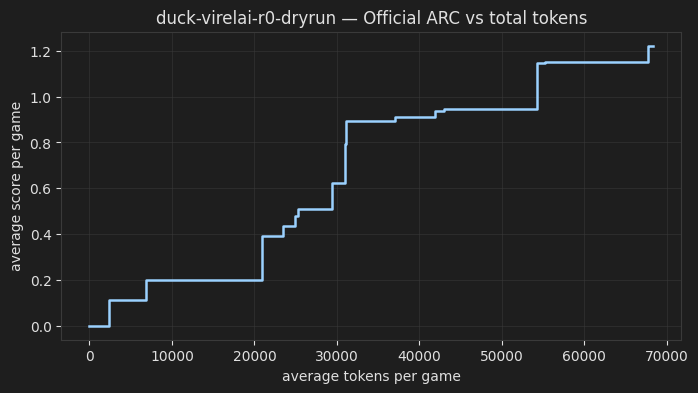
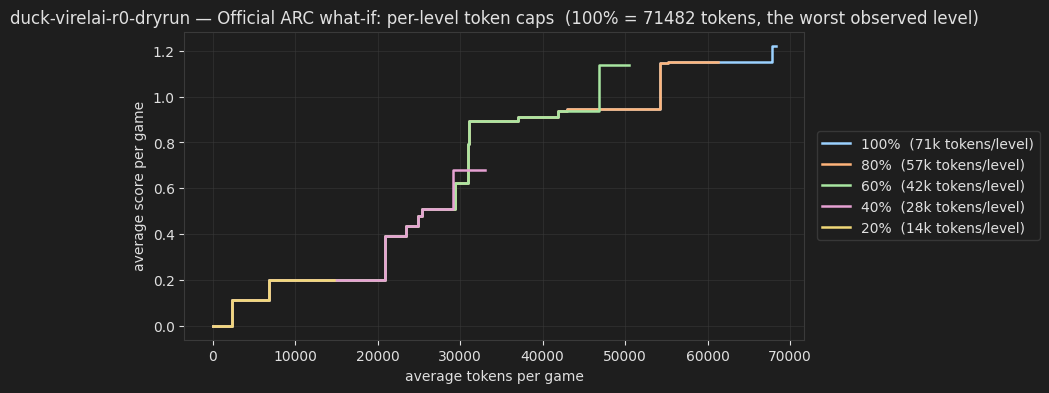
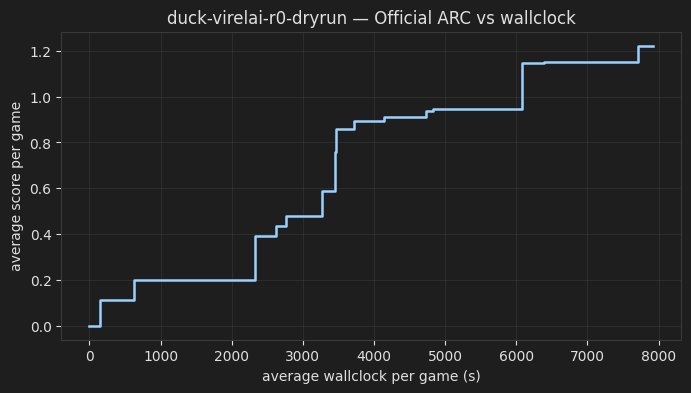
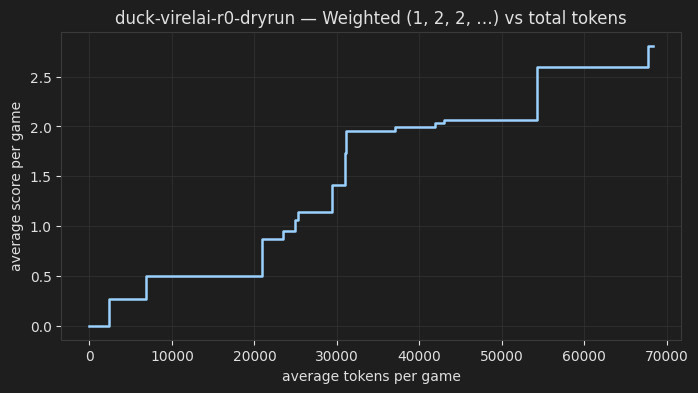
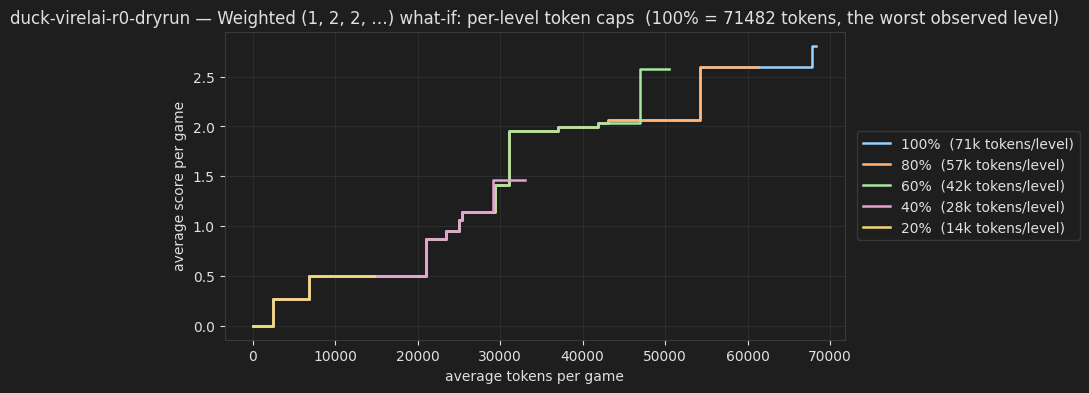
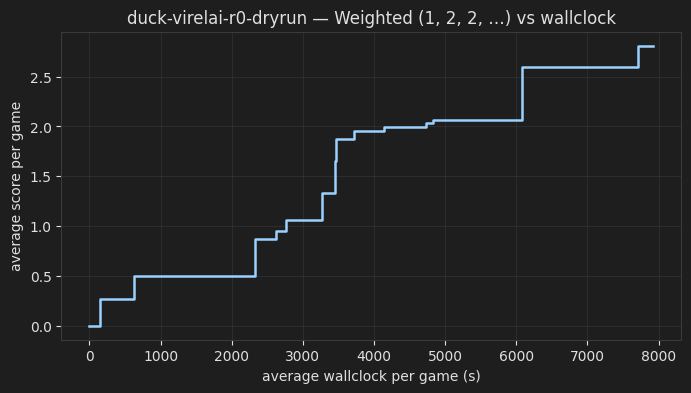
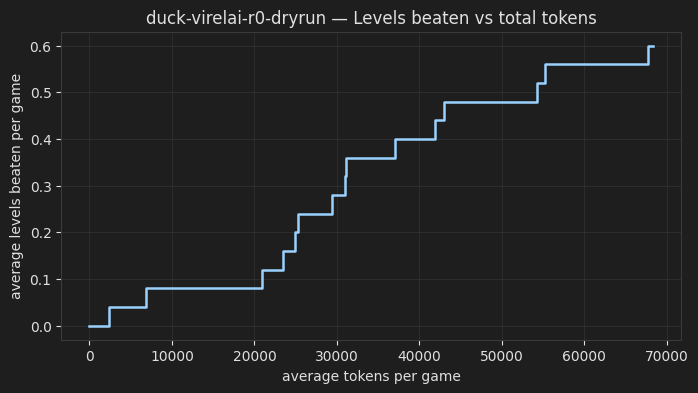
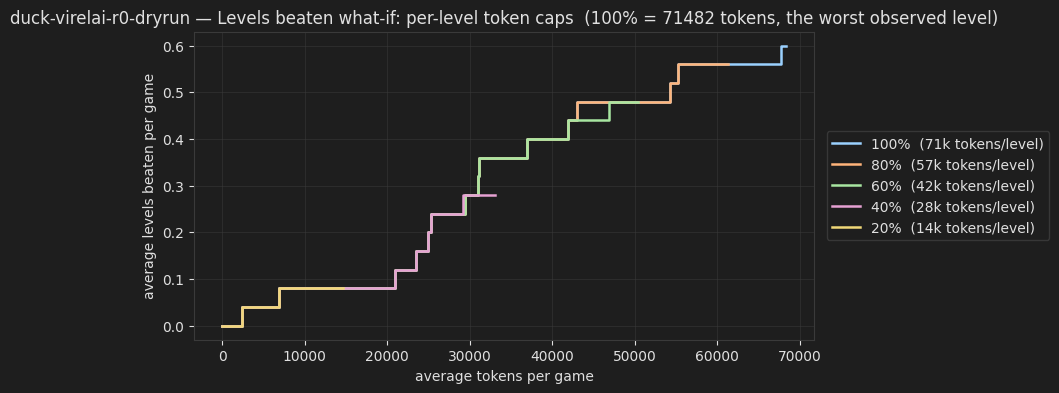
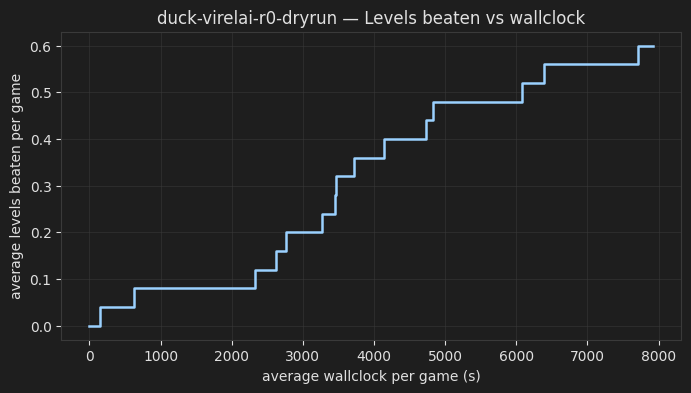
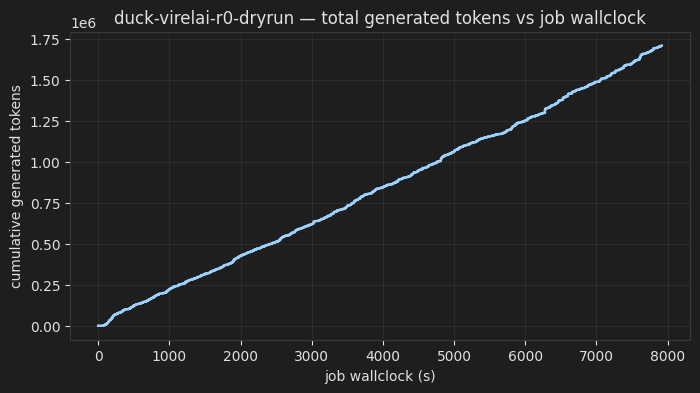
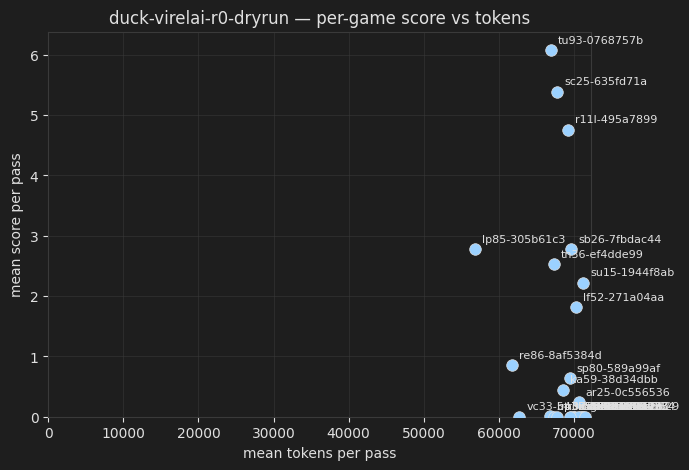
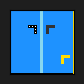
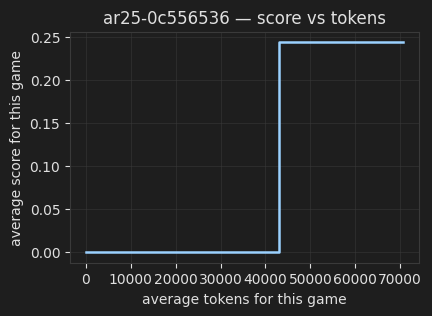
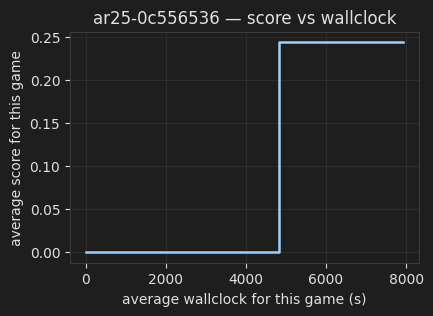
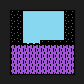
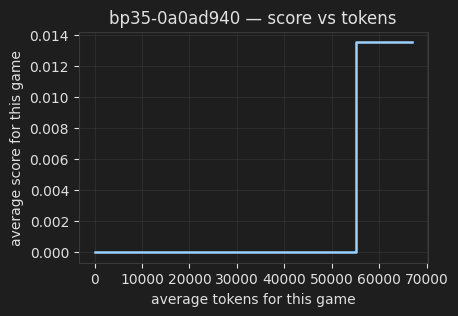
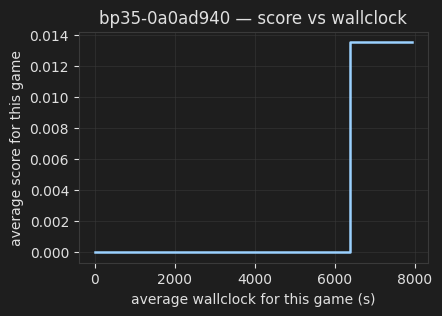
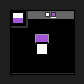
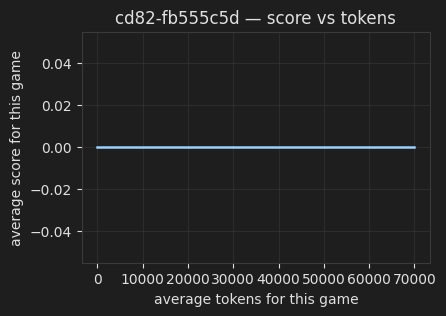
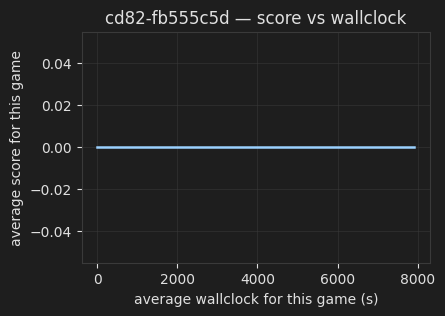
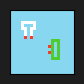
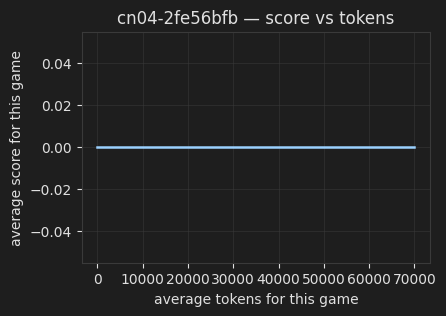
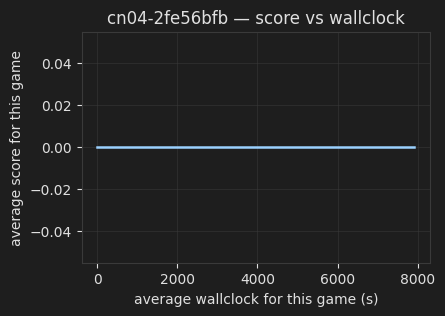
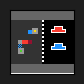
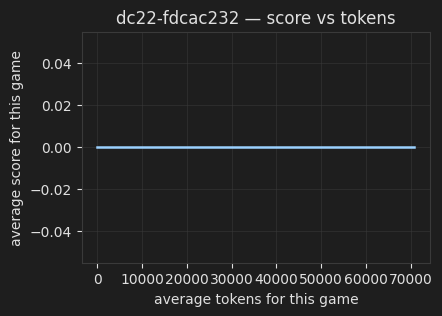
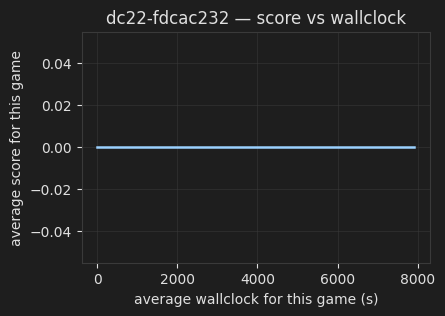
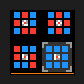
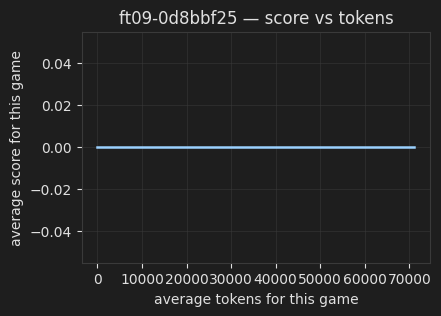
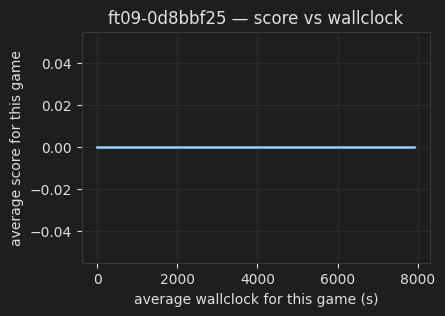
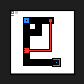
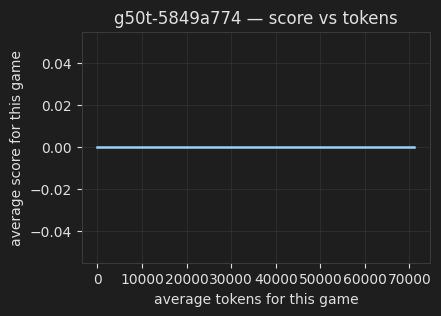
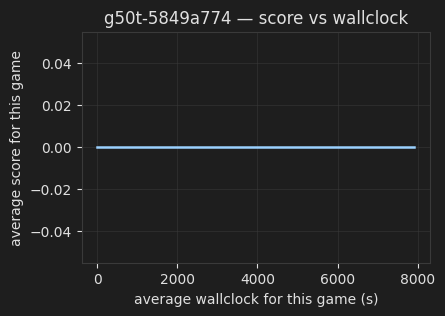
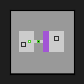
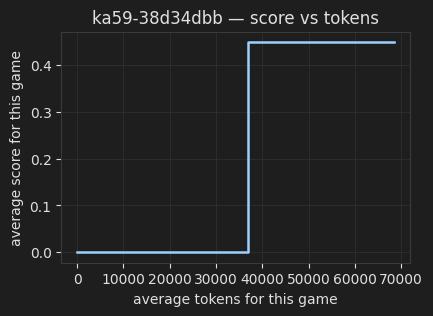
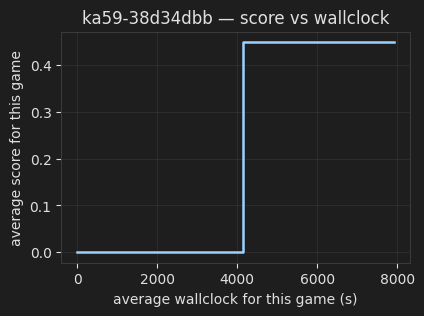
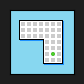
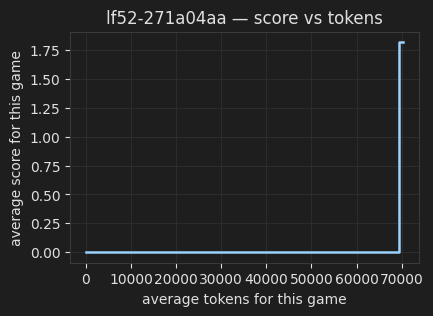
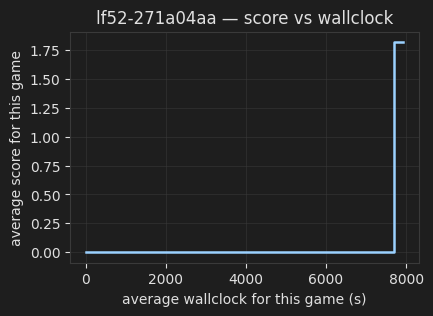
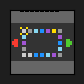
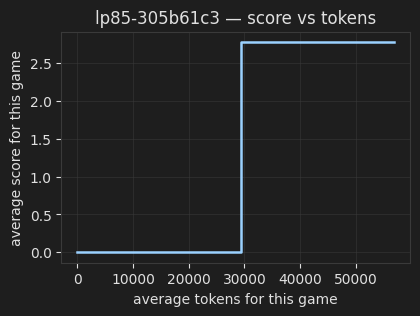
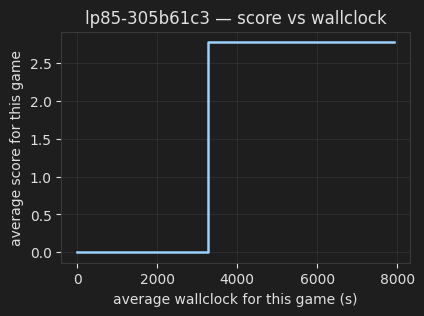
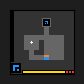
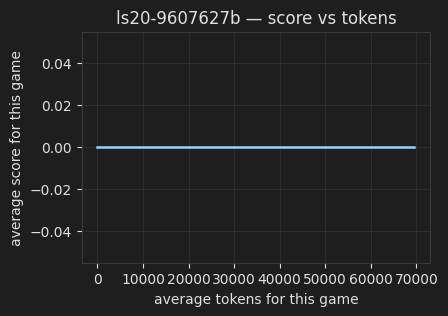
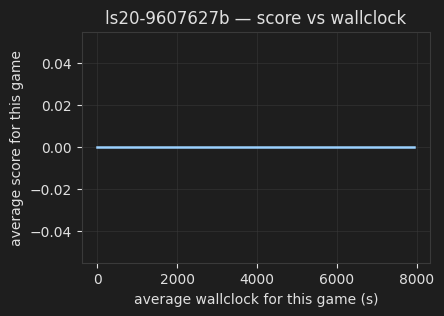
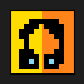
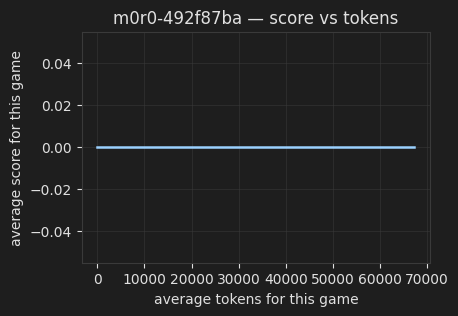
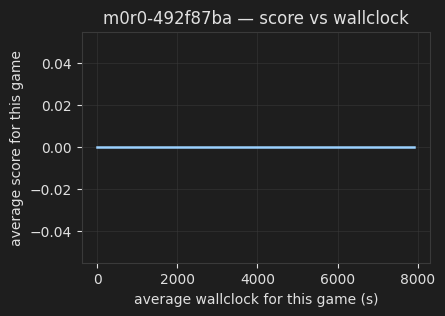
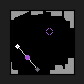
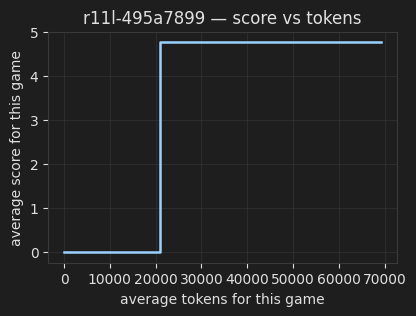
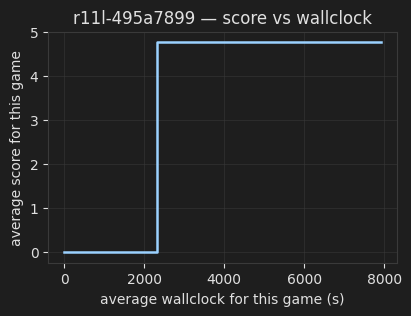
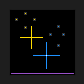
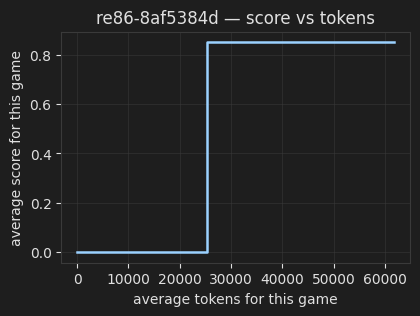
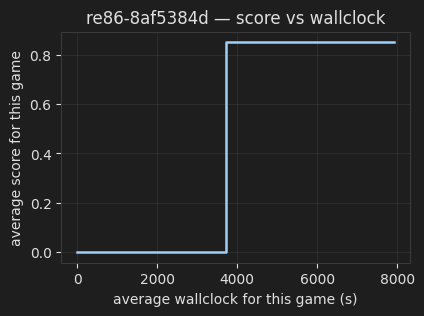
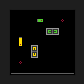
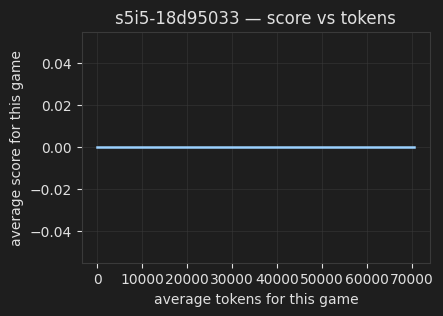
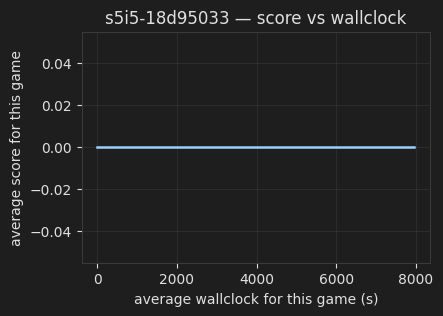
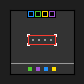
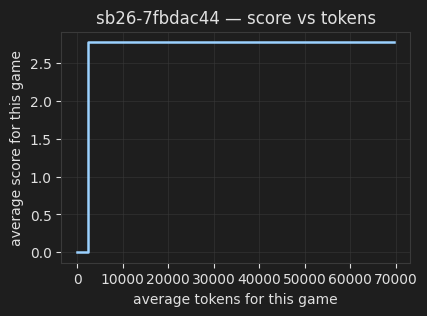
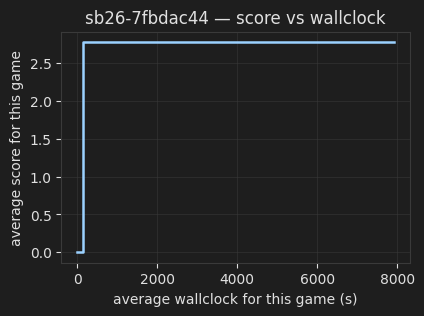
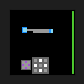
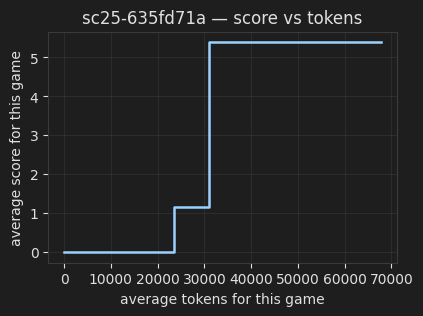
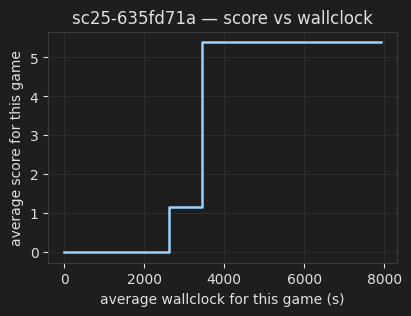
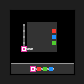
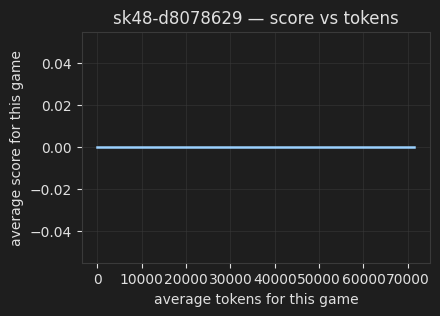
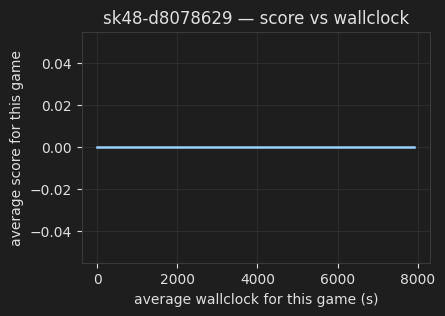
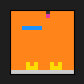
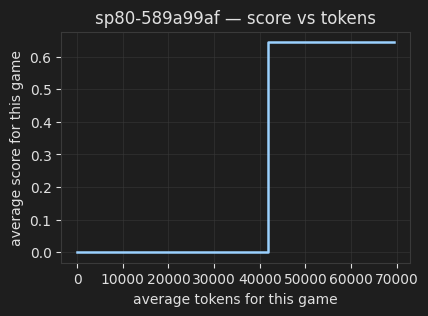
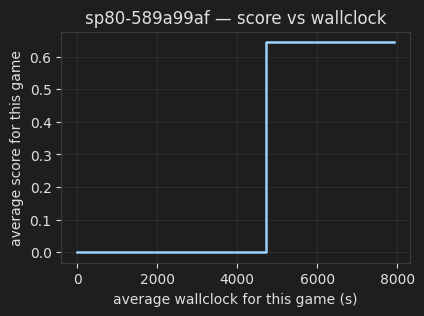
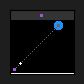
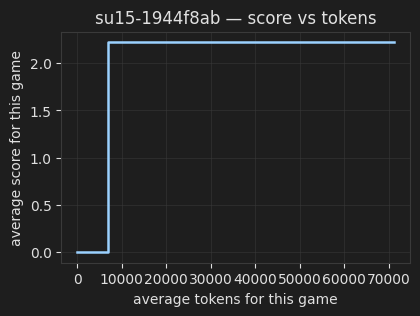
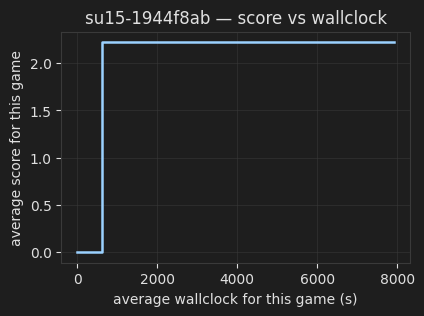
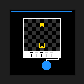
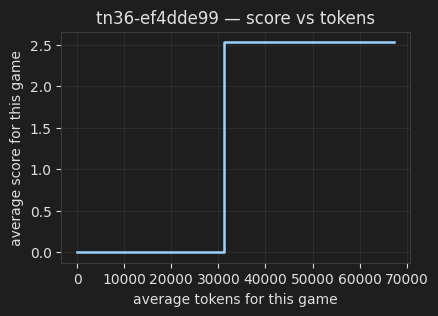
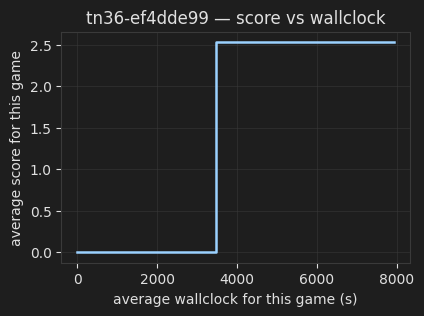
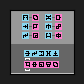
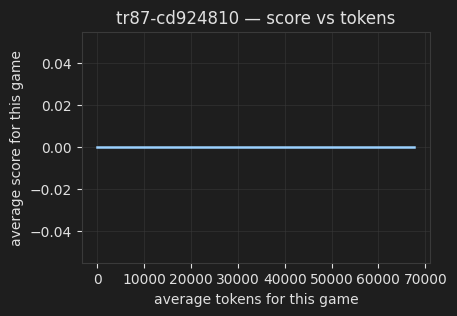
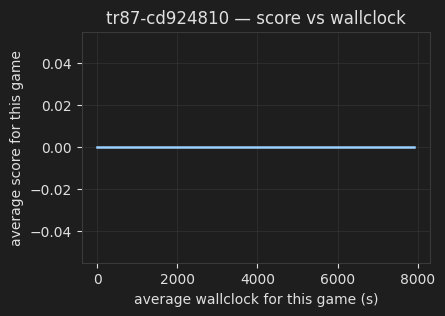
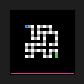
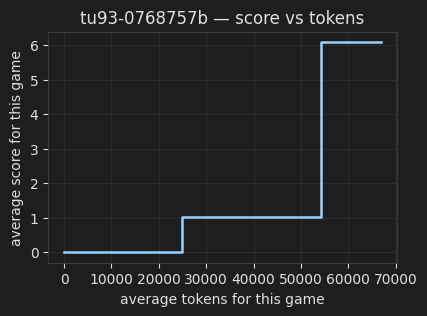
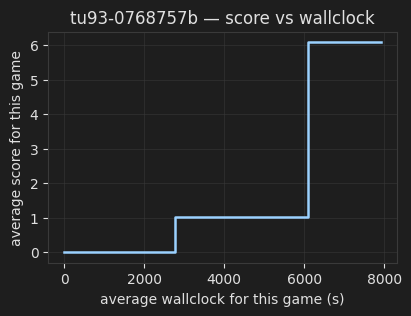
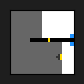
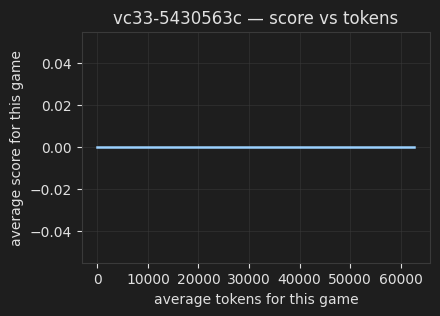
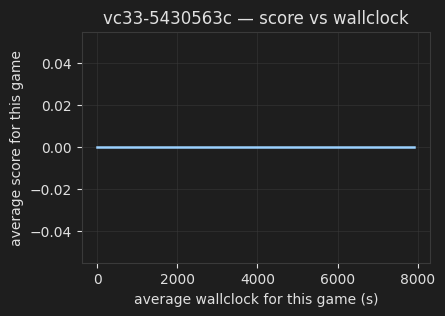
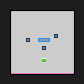
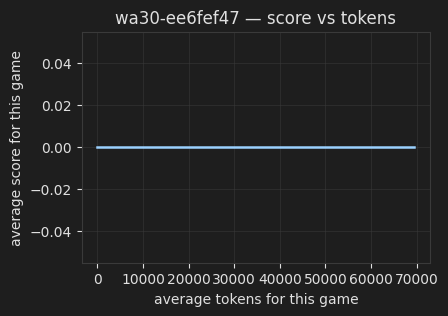
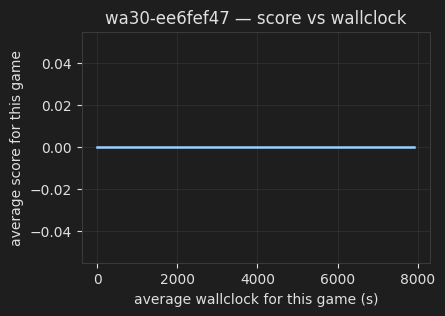
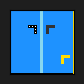
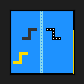
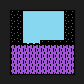
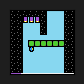
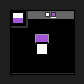
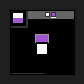
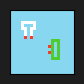
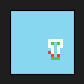
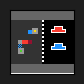
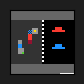
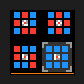
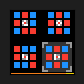
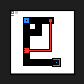
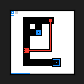
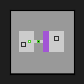
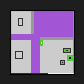
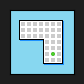
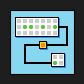
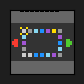
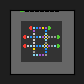
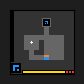
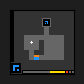
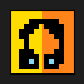
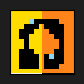
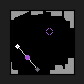
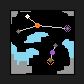
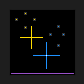
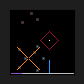
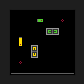
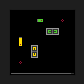
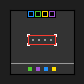
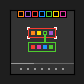
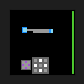
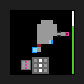
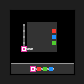
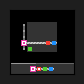
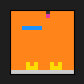
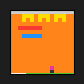
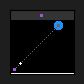
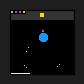
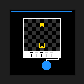
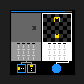
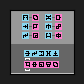
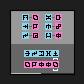
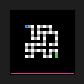
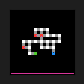
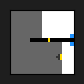
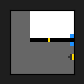
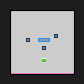
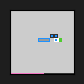

In [8]:
from html import escape

from IPython.display import HTML, display

diagnostics_html = WORKING_DIR / "diagnostics.html"
if diagnostics_html.is_file():
    # Isolate the full document in an iframe so its styles don't leak into the notebook.
    display(
        HTML(
            f'<iframe srcdoc="{escape(diagnostics_html.read_text(), quote=True)}" '
            'width="100%" height="900" style="border:0"></iframe>'
        )
    )
else:
    print("No diagnostics.html — minimal diagnostics (real submission) suppresses it.")